In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load dataset
cancer = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df['target'] = cancer.target

# Display first five rows
print("First five rows:")
display(df.head())

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [ ]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check class distribution
print("\nTarget Class Distribution:")
print(df['target'].value_counts())

# Display class names
print("\nClass Names:")
print(cancer.target_names)

Dataset Shape: (569, 31)

Missing Values:
0

Target Class Distribution:
target
1    357
0    212
Name: count, dtype: int64

Class Names:
['malignant' 'benign']


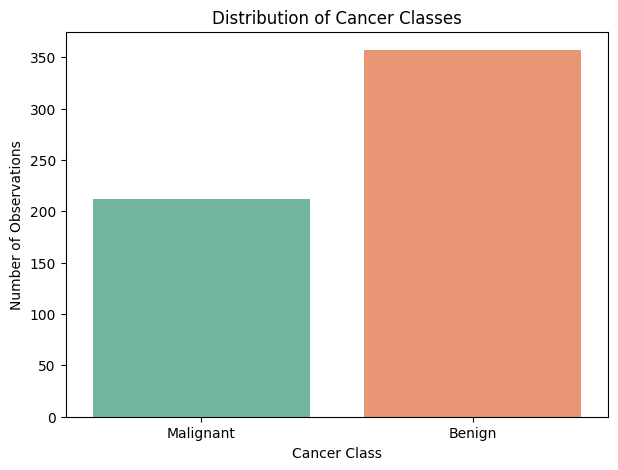

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=df['target'],
    hue=df['target'],
    palette='Set2',
    legend=False
)

plt.xticks([0, 1], ['Malignant', 'Benign'])

plt.title("Distribution of Cancer Classes")
plt.xlabel("Cancer Class")
plt.ylabel("Number of Observations")

plt.show()

In [ ]:
# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

print("\nTarget Values:")
print(y.unique())

Independent Variables Shape: (569, 30)
Dependent Variable Shape: (569,)

Target Values:
[0 1]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [ ]:
# Create StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Feature Scaling Completed Successfully!

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [ ]:
# Create Logistic Regression model
model = LogisticRegression(max_iter=5000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [ ]:
# Predict test data
y_pred = model.predict(X_test_scaled)

# Predict probabilities
y_prob = model.predict_proba(X_test_scaled)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 1 0 1 0 1 1 0 0 0]

Predicted Values:
[0 1 0 1 0 1 1 0 0 0]


Confusion Matrix:
[[41  1]
 [ 1 71]]


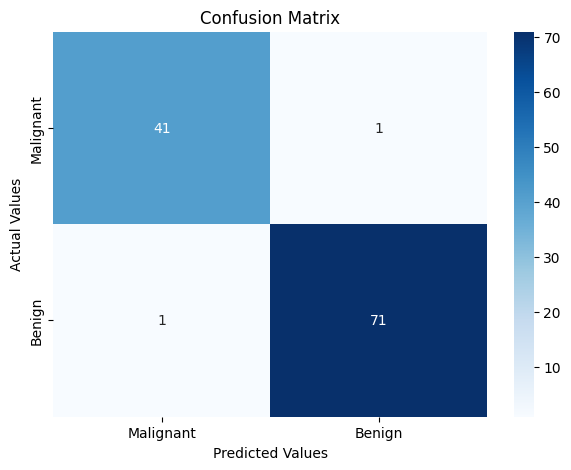

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate precision, recall and F1-score
# Here, malignant (class 0) is treated as the positive class
precision = precision_score(
    y_test, y_pred, pos_label=0
)

recall = recall_score(
    y_test, y_pred, pos_label=0
)

f1 = f1_score(
    y_test, y_pred, pos_label=0
)

print("Model Evaluation Results")
print("------------------------")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Model Evaluation Results
------------------------
Accuracy: 0.9825
Precision: 0.9762
Recall: 0.9762
F1-Score: 0.9762


In [ ]:
print("Classification Report:")
print("----------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Malignant', 'Benign']
    )
)

Classification Report:
----------------------
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



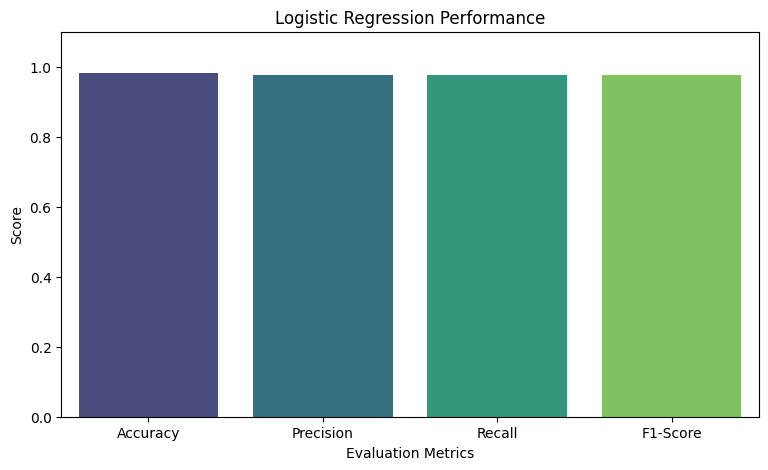

In [ ]:
metrics = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],

    'Score': [
        accuracy,
        precision,
        recall,
        f1
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=metrics,
    x='Metric',
    y='Score',
    hue='Metric',
    palette='viridis',
    legend=False
)

plt.ylim(0, 1.1)

plt.title("Logistic Regression Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")

plt.show()

In [ ]:
print("FINAL RESULT")
print("============")

print("Algorithm: Logistic Regression")

print("Classification Type: Binary Classification")

print("\nModel Performance:")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1-Score:", round(f1, 4))

print("\nModel trained and evaluated successfully!")

print("Binary Classification Experiment Completed!")

FINAL RESULT
Algorithm: Logistic Regression
Classification Type: Binary Classification

Model Performance:
Accuracy: 98.25 %
Precision: 0.9762
Recall: 0.9762
F1-Score: 0.9762

Model trained and evaluated successfully!
Binary Classification Experiment Completed!
